In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import category_encoders as ce

| Column Name | Data Type | Description | Example Values |
| :--- | :--- | :--- | :--- |
| `age` | Numeric | The age of the individual in years[cite: 1]. | 90, 82, 66, 54[cite: 1] |
| `workclass` | Categorical | The employment status or type of employer (contains missing values denoted as `NaN`)[cite: 1]. | Private, State-gov, Federal-gov, `NaN`[cite: 1] |
| `fnlwgt` | Numeric | "Final Weight" — the estimated number of people the census observation represents in the broader population[cite: 1]. | 77053, 132870, 186061[cite: 1] |
| `education` | Categorical | The highest level of education achieved by the individual[cite: 1]. | HS-grad, Some-college, Doctorate[cite: 1] |
| `education.num` | Numeric | The numerical equivalent/code for the highest level of education[cite: 1]. | 9, 10, 4, 16[cite: 1] |
| `marital.status` | Categorical | The marital status of the individual[cite: 1]. | Widowed, Divorced, Separated, Never-married[cite: 1] |
| `occupation` | Categorical | The general type of job or occupation (contains missing values denoted as `NaN`)[cite: 1]. | Exec-managerial, Prof-specialty, Craft-repair[cite: 1] |
| `relationship` | Categorical | The individual's role or relationship status within their household[cite: 1]. | Not-in-family, Unmarried, Own-child[cite: 1] |
| `race` | Categorical | The racial background of the individual[cite: 1]. | White, Black[cite: 1] |
| `sex` | Categorical | The gender of the individual[cite: 1]. | Female, Male[cite: 1] |
| `capital.gain` | Numeric | Capital gains recorded from investments or asset sales[cite: 1]. | 0[cite: 1] |
| `hours.per.week` | Numeric | The number of hours the individual works per week[cite: 2]. | 40, 18, 60, 35[cite: 2] |
| `native.country` | Categorical | The country of origin or native country (contains missing values denoted as `NaN`)[cite: 2]. | United-States, `NaN`[cite: 2] |
| `income` | Categorical | The target variable indicating whether annual income exceeds $50,000[cite: 2]. | <=50K, >50K[cite: 2] |

In [2]:
df = pd.read_csv(r"Adult Census Income.csv",na_values='?')

In [3]:
df 

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [4]:
df.duplicated().sum()

24

In [5]:
df = df.drop_duplicates()

In [6]:
df.head(20)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
7,74,State-gov,88638,Doctorate,16,Never-married,Prof-specialty,Other-relative,White,Female,0,3683,20,United-States,>50K
8,68,Federal-gov,422013,HS-grad,9,Divorced,Prof-specialty,Not-in-family,White,Female,0,3683,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,NaN,>50K


In [7]:
df.isnull().sum().sort_values(ascending= False)
nullCols = ['occupation','workclass','native.country']

In [8]:
df[df.isnull().any(axis= 1)]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,NaN,>50K
14,51,NaN,172175,Doctorate,16,Never-married,NaN,Not-in-family,White,Male,0,2824,40,United-States,>50K
18,22,Private,119592,Assoc-acdm,12,Never-married,Handlers-cleaners,Not-in-family,Black,Male,0,2824,40,NaN,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,NaN,320084,Bachelors,13,Married-civ-spouse,NaN,Wife,White,Female,0,0,55,United-States,>50K
32534,30,NaN,33811,Bachelors,13,Never-married,NaN,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,NaN,287372,Doctorate,16,Married-civ-spouse,NaN,Husband,White,Male,0,0,10,United-States,>50K
32543,41,NaN,202822,HS-grad,9,Separated,NaN,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [9]:
df[df['occupation'].isnull()]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
14,51,NaN,172175,Doctorate,16,Never-married,NaN,Not-in-family,White,Male,0,2824,40,United-States,>50K
24,61,NaN,135285,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2603,32,United-States,<=50K
44,71,NaN,100820,HS-grad,9,Married-civ-spouse,NaN,Husband,White,Male,0,2489,15,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,NaN,320084,Bachelors,13,Married-civ-spouse,NaN,Wife,White,Female,0,0,55,United-States,>50K
32534,30,NaN,33811,Bachelors,13,Never-married,NaN,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,NaN,287372,Doctorate,16,Married-civ-spouse,NaN,Husband,White,Male,0,0,10,United-States,>50K
32543,41,NaN,202822,HS-grad,9,Separated,NaN,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [10]:
df['occupation'].value_counts()

occupation
Prof-specialty       4136
Craft-repair         4094
Exec-managerial      4065
Adm-clerical         3768
Sales                3650
Other-service        3291
Machine-op-inspct    2000
Transport-moving     1597
Handlers-cleaners    1369
Farming-fishing       992
Tech-support          927
Protective-serv       649
Priv-house-serv       147
Armed-Forces            9
Name: count, dtype: int64

In [11]:
for col in nullCols:
    print(df[col].nunique())
    print(df[col].unique())
    print("_______________________________________________________")

14
[nan 'Exec-managerial' 'Machine-op-inspct' 'Prof-specialty'
 'Other-service' 'Adm-clerical' 'Craft-repair' 'Transport-moving'
 'Handlers-cleaners' 'Sales' 'Farming-fishing' 'Tech-support'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']
_______________________________________________________
8
[nan 'Private' 'State-gov' 'Federal-gov' 'Self-emp-not-inc' 'Self-emp-inc'
 'Local-gov' 'Without-pay' 'Never-worked']
_______________________________________________________
41
['United-States' nan 'Mexico' 'Greece' 'Vietnam' 'China' 'Taiwan' 'India'
 'Philippines' 'Trinadad&Tobago' 'Canada' 'South' 'Holand-Netherlands'
 'Puerto-Rico' 'Poland' 'Iran' 'England' 'Germany' 'Italy' 'Japan' 'Hong'
 'Honduras' 'Cuba' 'Ireland' 'Cambodia' 'Peru' 'Nicaragua'
 'Dominican-Republic' 'Haiti' 'El-Salvador' 'Hungary' 'Columbia'
 'Guatemala' 'Jamaica' 'Ecuador' 'France' 'Yugoslavia' 'Scotland'
 'Portugal' 'Laos' 'Thailand' 'Outlying-US(Guam-USVI-etc)']
____________________________________________________

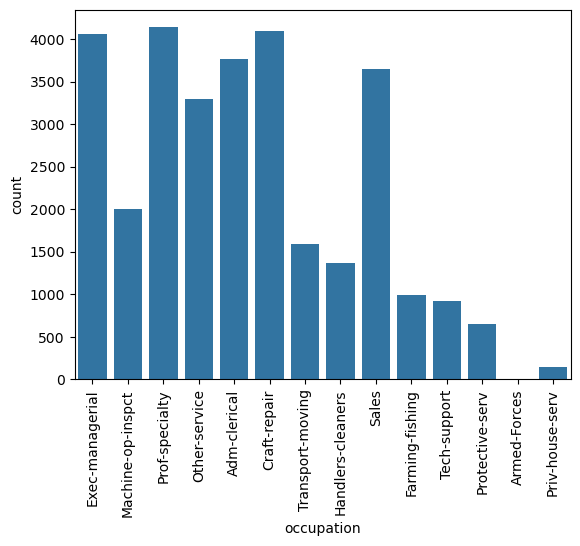

In [12]:
sns.countplot(data = df, x = nullCols[0])
plt.xticks(rotation = 90)
plt.show()


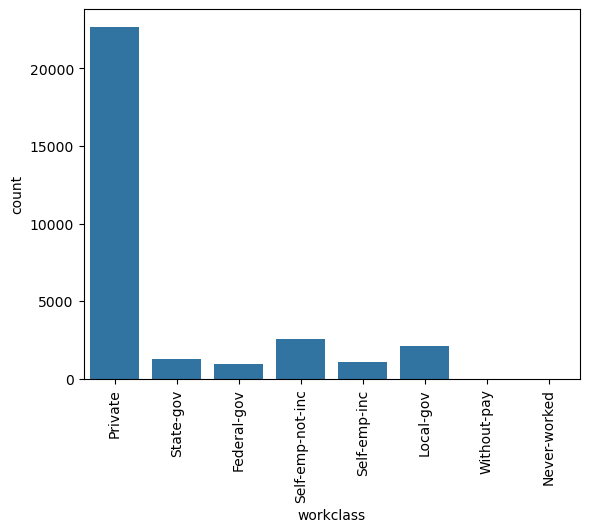

In [13]:
sns.countplot(data = df, x = nullCols[1])
plt.xticks(rotation = 90)
plt.show()


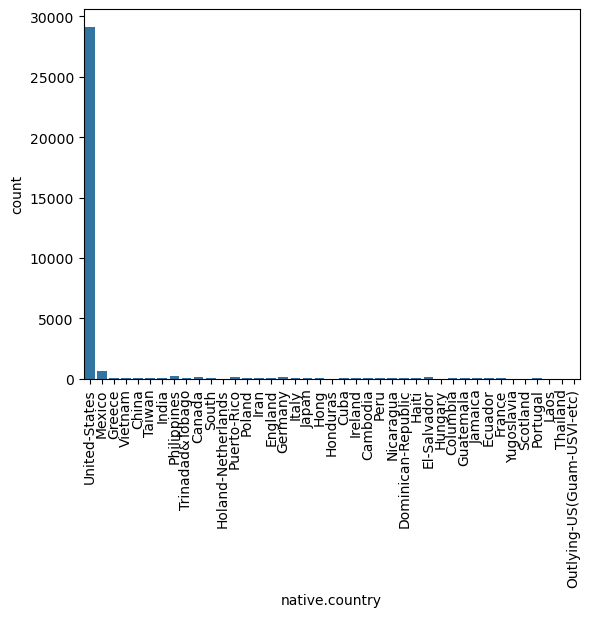

In [14]:
sns.countplot(data = df, x = nullCols[2])
plt.xticks(rotation = 90)
plt.show()


In [15]:
df = df.dropna()

In [16]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

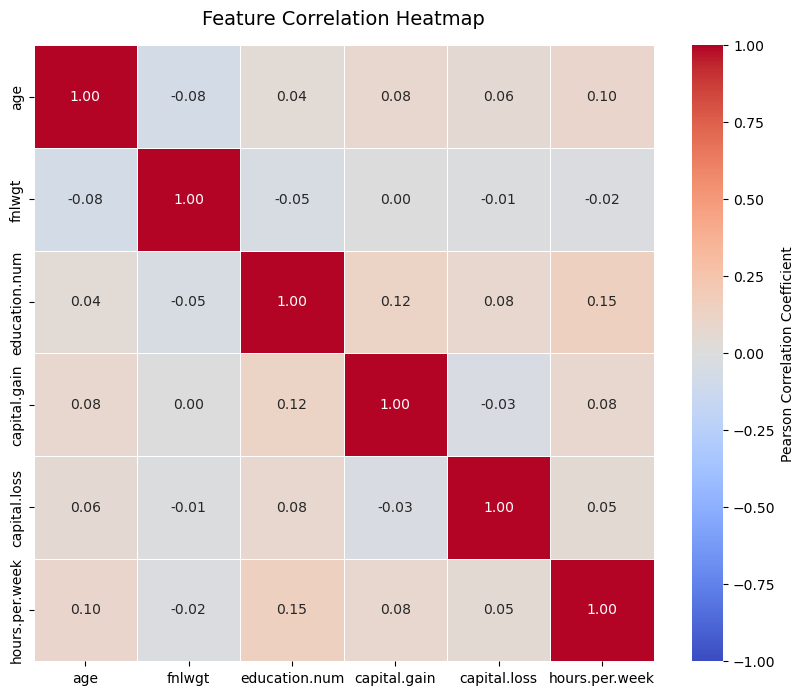

In [17]:
plt.figure(figsize=(10, 8))


sns.heatmap(
    df.select_dtypes("number").corr(),
    annot=True,  
    fmt=".2f",  
    cmap="coolwarm",  
    vmin=-1,  
    vmax=1,  
    linewidths=0.5,  
    cbar_kws={"label": "Pearson Correlation Coefficient"},
)

plt.title("Feature Correlation Heatmap", fontsize=14, pad=15)
plt.show()

In [18]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,30139.000000,3.013900e+04,30139.000000,30139.000000,30139.000000,30139.000000
mean,38.441720,1.897950e+05,10.122532,1092.841202,88.439928,40.934703
std,13.131426,1.056586e+05,2.548738,7409.110596,404.445239,11.978753
min,17.000000,1.376900e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.176275e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.784170e+05,10.000000,0.000000,0.000000,40.000000
75%,47.000000,2.376045e+05,13.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [19]:
df['capital.gain'].value_counts()

capital.gain
0        27601
15024      337
7688       270
7298       240
99999      148
         ...  
7978         1
5060         1
2538         1
401          1
22040        1
Name: count, Length: 118, dtype: int64

In [20]:
df_encoded = df.copy()


object_cols = df_encoded.select_dtypes(include=['object']).columns


label_encoder = LabelEncoder()

for col in object_cols:
  
    
    df_encoded[col] = df_encoded[col].fillna('Unknown')

    
    df_encoded[col] = label_encoder.fit_transform(df_encoded[col])


print(df_encoded.head())

   age  workclass  fnlwgt  education  education.num  marital.status  \
1   82          2  132870         11              9               6   
3   54          2  140359          5              4               0   
4   41          2  264663         15             10               5   
5   34          2  216864         11              9               0   
6   38          2  150601          0              6               5   

   occupation  relationship  race  sex  capital.gain  capital.loss  \
1           3             1     4    0             0          4356   
3           6             4     4    0             0          3900   
4           9             3     4    0             0          3900   
5           7             4     4    0             0          3770   
6           0             4     4    1             0          3770   

   hours.per.week  native.country  income  
1              18              38       0  
3              40              38       0  
4              40   

In [21]:
from sklearn.model_selection import train_test_split


y = df_encoded['income']
X = df_encoded.drop(columns=['income'])


x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=.20,random_state=10)

In [22]:
df_encoded['income'].value_counts()

income
0    22633
1     7506
Name: count, dtype: int64

In [23]:
scaler = StandardScaler()

In [24]:
x_train[['fnlwgt','age','hours.per.week','native.country']] = scaler.fit_transform(x_train[['fnlwgt','age','hours.per.week','native.country']])
x_test[['fnlwgt','age','hours.per.week','native.country']] = scaler.transform(x_test[['fnlwgt','age','hours.per.week','native.country']])

In [25]:
x_train

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
11598,0.195772,1,1.532159,7,12,4,3,1,4,1,0,0,-0.079174,0.262184
18298,1.264409,2,-0.144523,11,9,2,13,0,4,1,0,0,-0.749751,0.262184
4568,-0.872866,2,1.052446,9,13,4,2,1,4,1,0,0,0.759047,0.262184
16617,0.730090,2,-0.903687,9,13,2,2,0,4,1,0,0,1.178157,0.262184
24405,0.424765,4,-1.003214,9,13,0,3,1,4,1,0,0,1.597268,0.262184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30245,-0.338547,5,-0.818347,8,11,4,0,4,4,0,0,0,-0.079174,0.262184
19123,-1.407184,2,-1.481387,15,10,4,7,3,4,0,0,0,-1.336505,0.262184
31531,-0.949197,2,-0.743943,11,9,4,0,4,4,0,0,0,-0.498284,0.262184
7868,1.569734,2,0.037262,11,9,0,3,1,4,0,0,0,-0.079174,0.262184


In [26]:
x_test

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
26138,1.264409,2,-0.174721,11,9,0,2,4,2,1,0,0,0.591403,0.262184
6398,-0.872866,2,0.204322,1,7,4,5,2,2,1,0,0,-0.079174,0.262184
28167,-0.338547,4,-0.116385,7,12,4,2,1,4,1,0,0,-0.079174,0.262184
15269,2.333046,2,0.182262,11,9,2,0,0,4,1,0,0,-0.414462,0.262184
28576,1.340740,2,-0.074580,9,13,2,12,0,4,1,0,0,0.591403,0.262184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31020,-0.185885,2,1.011775,15,10,0,2,1,4,0,0,0,-0.330640,0.262184
30553,-0.491210,4,-0.066414,12,14,4,9,1,4,1,0,0,-0.079174,0.262184
17979,-0.185885,2,-1.069064,11,9,4,7,3,2,1,0,0,-0.498284,0.262184
30185,1.340740,4,-1.290981,1,7,2,2,0,4,1,0,0,-1.755616,0.262184


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [28]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(x_train, y_train)
y_pred_lr = lr_model.predict(x_test)


e:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [29]:
print(f"Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_lr)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))



Logistic Regression Accuracy: 81.62%

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.93      0.88      4505
           1       0.70      0.47      0.56      1523

    accuracy                           0.82      6028
   macro avg       0.77      0.70      0.72      6028
weighted avg       0.80      0.82      0.80      6028

Confusion Matrix:
 [[4203  302]
 [ 806  717]]


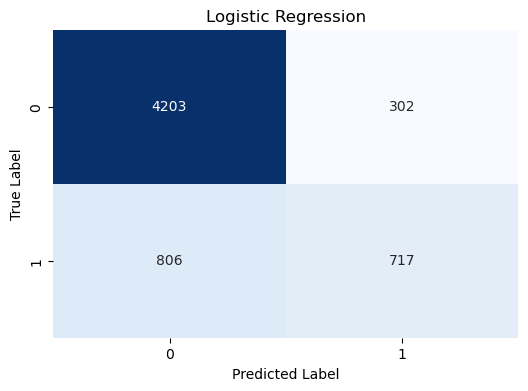

In [30]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [31]:
from sklearn.neighbors import KNeighborsClassifier

In [32]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train, y_train)

y_pred_knn = knn_model.predict(x_test)

In [33]:
print(f"KNN Accuracy: {accuracy_score(y_test, y_pred_knn)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_knn))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))

KNN Accuracy: 84.77%

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.91      0.90      4505
           1       0.71      0.67      0.69      1523

    accuracy                           0.85      6028
   macro avg       0.80      0.79      0.79      6028
weighted avg       0.85      0.85      0.85      6028

Confusion Matrix:
 [[4089  416]
 [ 502 1021]]


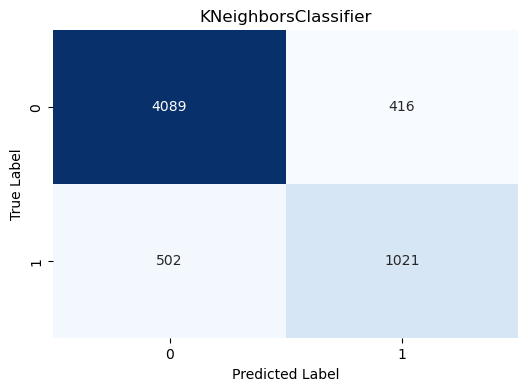

In [34]:
cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('KNeighborsClassifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [35]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[18128., 5983.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.75,0.25]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int32](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.05641
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['age','workclass','fnlwgt',...,'capital.loss','hours.per.week', 'native.country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 14)","[[ -0.14, 2.19, 0. ,..., 53.83, -0.13, -0.01], [ 0.42, 2.23, -0.01,...,188.48, 0.4 , 0.04]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 14)","[[ 1.11, 0.91, 1.07,..., 97273.26, 1.05, 1.08], [ 0.66, 1.13, 1.01,...,342414.54, 0.86, 0.99]]"


In [36]:
y_pred_nb = nb_model.predict(x_test)
print(f"Naive Bayes Accuracy: {accuracy_score(y_test, y_pred_nb)*100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy: 79.10%

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.95      0.87      4505
           1       0.68      0.33      0.44      1523

    accuracy                           0.79      6028
   macro avg       0.74      0.64      0.66      6028
weighted avg       0.77      0.79      0.76      6028

Confusion Matrix:
 [[4270  235]
 [1025  498]]


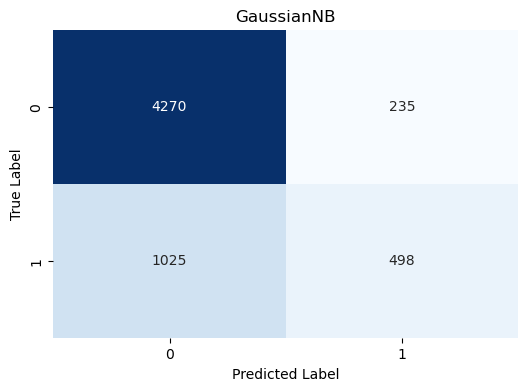

In [37]:
cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('GaussianNB')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [38]:
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [40]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [41]:
from tqdm import tqdm

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[4212  293]
 [ 808  715]]


e:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


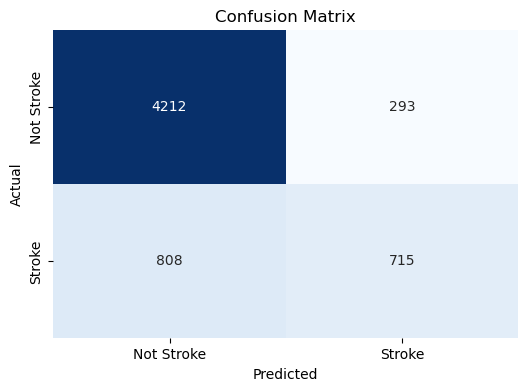


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.93      0.88      4505
      Stroke       0.71      0.47      0.56      1523

    accuracy                           0.82      6028
   macro avg       0.77      0.70      0.72      6028
weighted avg       0.81      0.82      0.80      6028

ROC-AUC: 0.8522350958991359


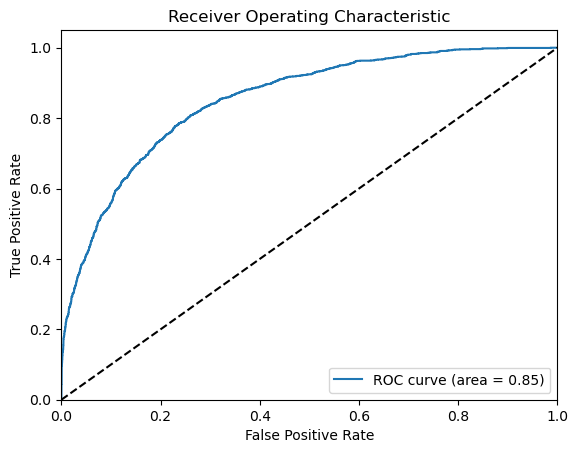

PR AUC: 0.6924578674116881


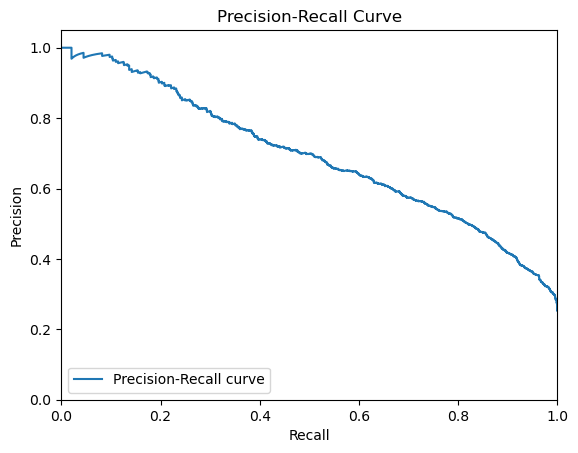

  8%|▊         | 1/13 [00:06<01:23,  6.92s/it]


Confusion Matrix:
 [[4089  416]
 [ 502 1021]]


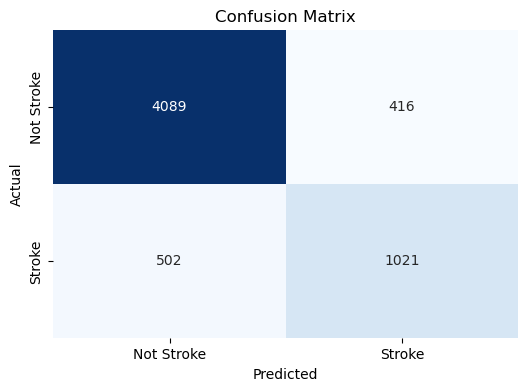


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.91      0.90      4505
      Stroke       0.71      0.67      0.69      1523

    accuracy                           0.85      6028
   macro avg       0.80      0.79      0.79      6028
weighted avg       0.85      0.85      0.85      6028

ROC-AUC: 0.8780831541229086


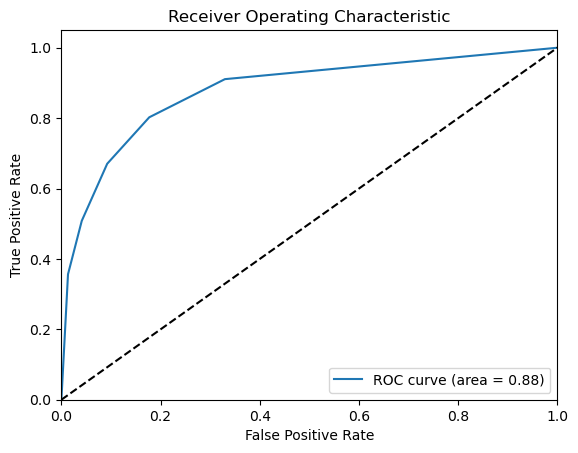

PR AUC: 0.7134238360562062


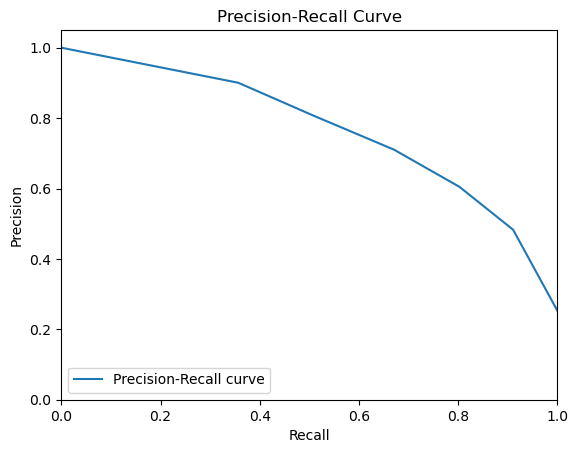

 15%|█▌        | 2/13 [00:19<01:50, 10.08s/it]e:\anaconda\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[4365  140]
 [1107  416]]


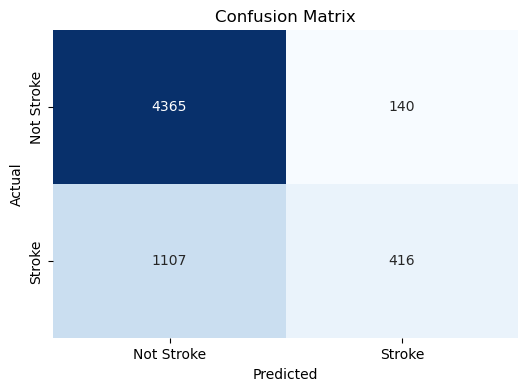


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.97      0.88      4505
      Stroke       0.75      0.27      0.40      1523

    accuracy                           0.79      6028
   macro avg       0.77      0.62      0.64      6028
weighted avg       0.79      0.79      0.76      6028

ROC-AUC: 0.8359918176564597


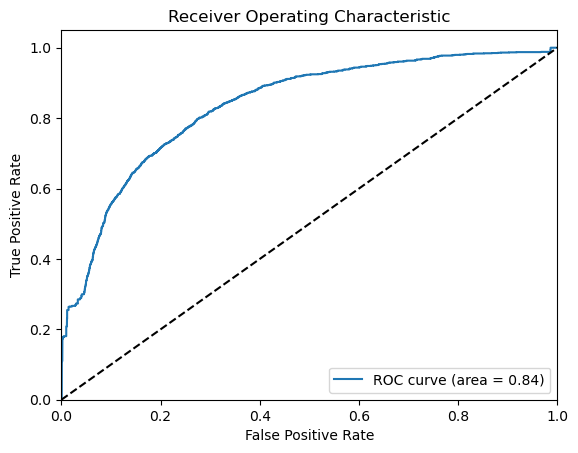

PR AUC: 0.6623120361882893


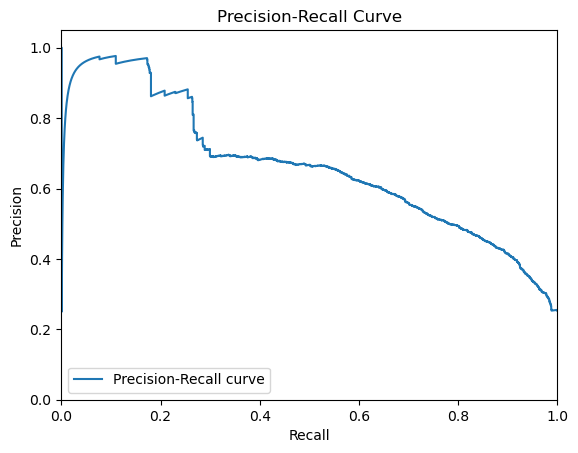

 23%|██▎       | 3/13 [04:09<18:25, 110.55s/it]


Confusion Matrix:
 [[3864  641]
 [ 570  953]]


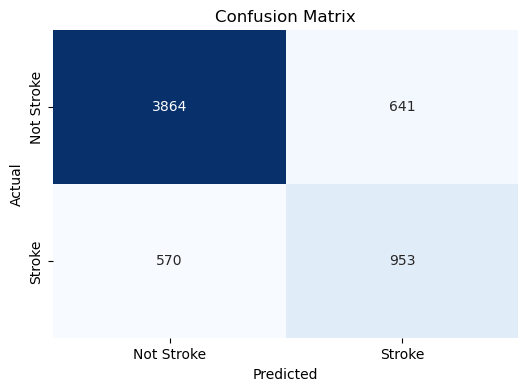


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.86      0.86      4505
      Stroke       0.60      0.63      0.61      1523

    accuracy                           0.80      6028
   macro avg       0.73      0.74      0.74      6028
weighted avg       0.80      0.80      0.80      6028

ROC-AUC: 0.7416846241463668


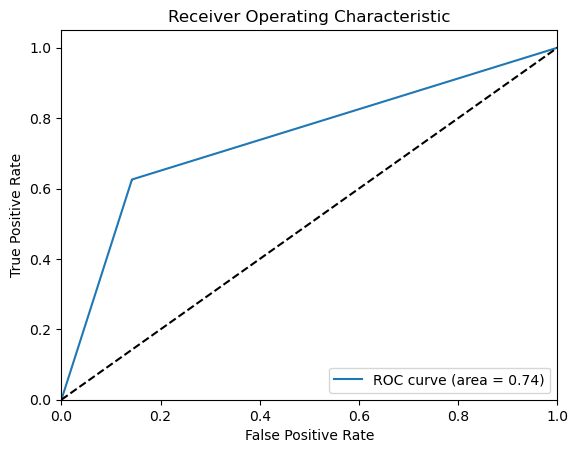

PR AUC: 0.4686672303419983


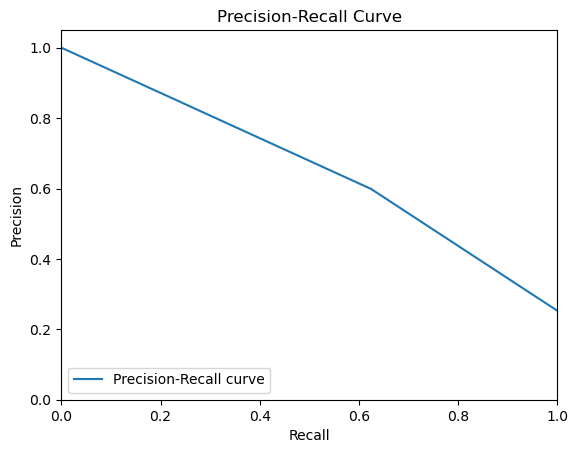

 31%|███       | 4/13 [04:10<10:06, 67.38s/it] 


Confusion Matrix:
 [[4270  235]
 [1025  498]]


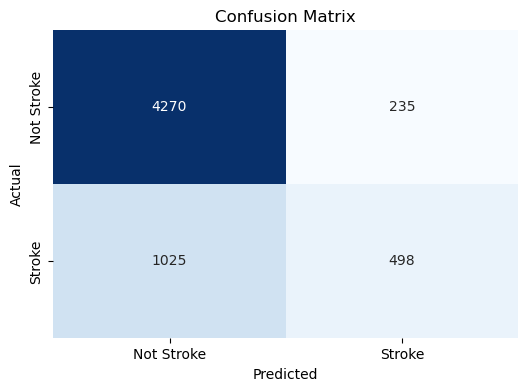


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.81      0.95      0.87      4505
      Stroke       0.68      0.33      0.44      1523

    accuracy                           0.79      6028
   macro avg       0.74      0.64      0.66      6028
weighted avg       0.77      0.79      0.76      6028

ROC-AUC: 0.8547223009671168


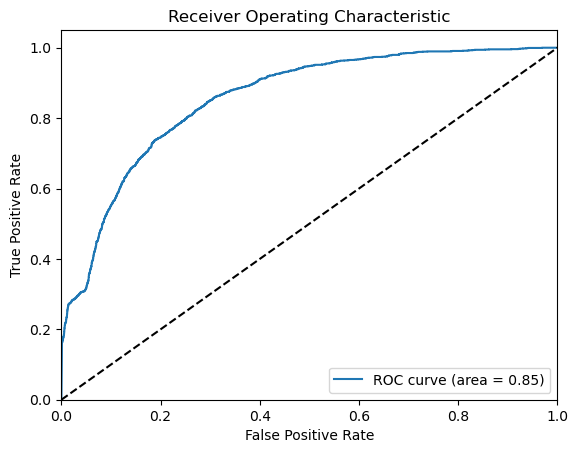

PR AUC: 0.6837859476416844


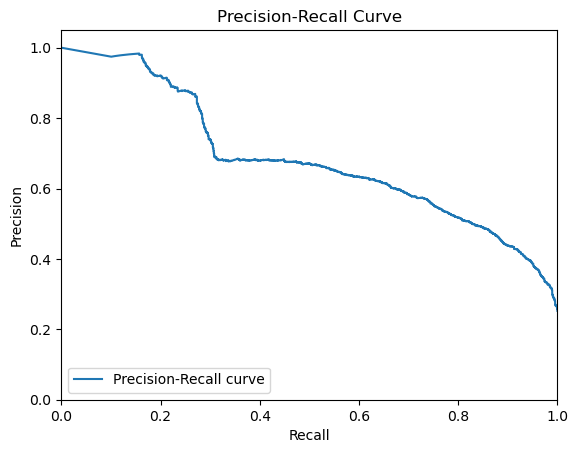

 38%|███▊      | 5/13 [04:11<05:47, 43.38s/it]


Confusion Matrix:
 [[4159  346]
 [ 578  945]]


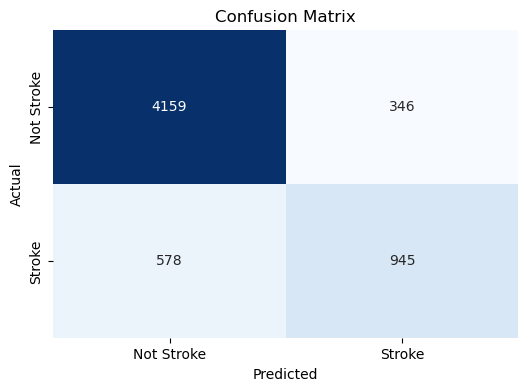


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.92      0.90      4505
      Stroke       0.73      0.62      0.67      1523

    accuracy                           0.85      6028
   macro avg       0.80      0.77      0.79      6028
weighted avg       0.84      0.85      0.84      6028

ROC-AUC: 0.8995561217090808


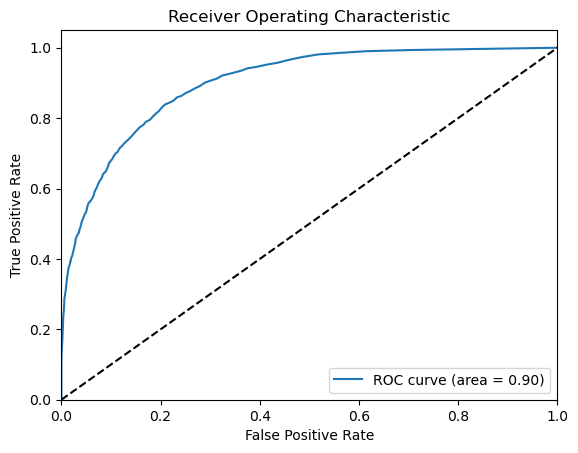

PR AUC: 0.7766144129626704


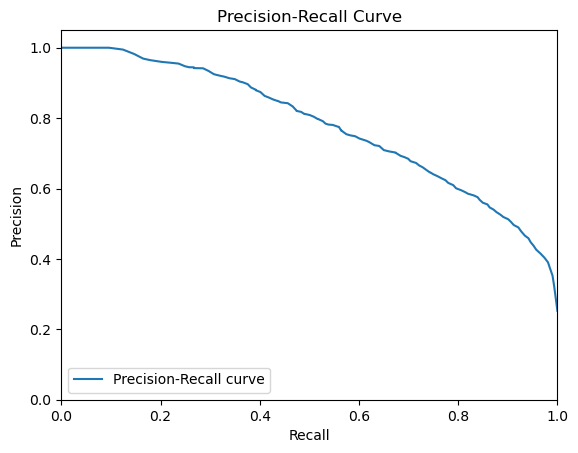

 46%|████▌     | 6/13 [04:16<03:33, 30.51s/it]


Confusion Matrix:
 [[4110  395]
 [ 590  933]]


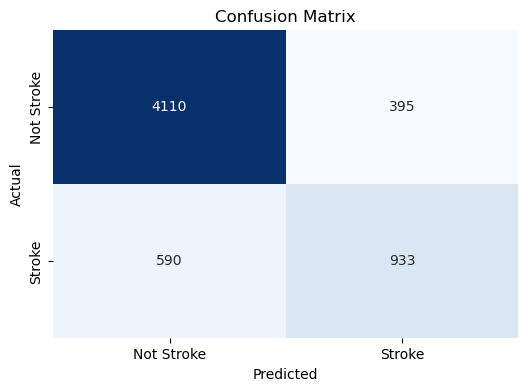


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.91      0.89      4505
      Stroke       0.70      0.61      0.65      1523

    accuracy                           0.84      6028
   macro avg       0.79      0.76      0.77      6028
weighted avg       0.83      0.84      0.83      6028

ROC-AUC: 0.8864589064605388


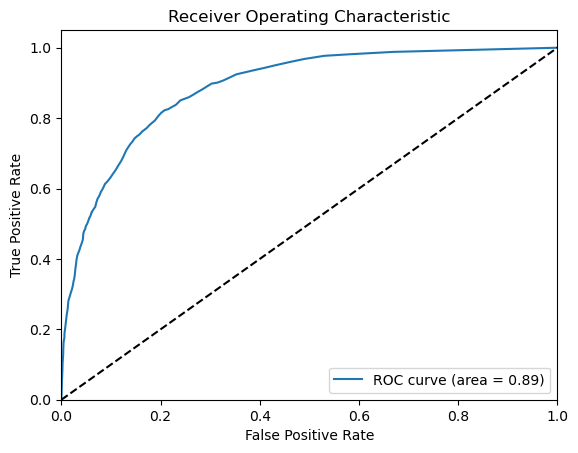

PR AUC: 0.7307524603353989


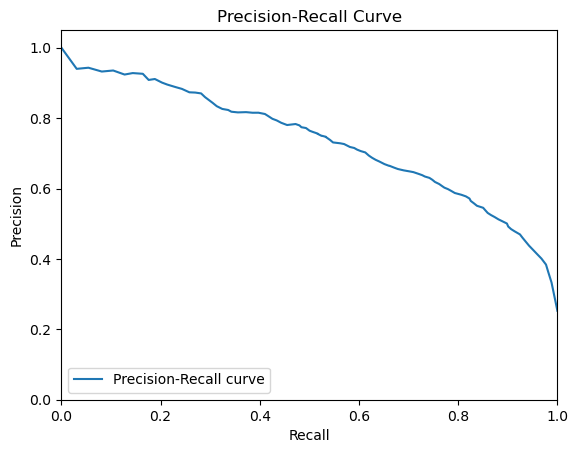

 54%|█████▍    | 7/13 [04:22<02:14, 22.38s/it]


Confusion Matrix:
 [[4187  318]
 [ 632  891]]


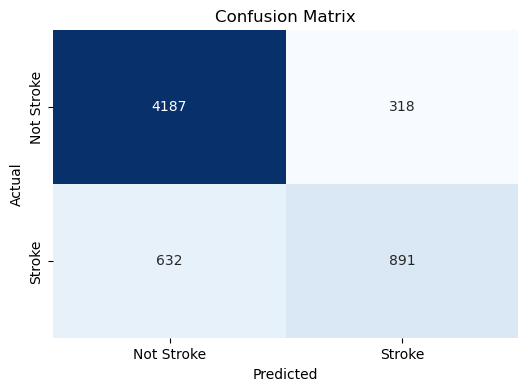


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.93      0.90      4505
      Stroke       0.74      0.59      0.65      1523

    accuracy                           0.84      6028
   macro avg       0.80      0.76      0.78      6028
weighted avg       0.84      0.84      0.84      6028

ROC-AUC: 0.8963855000244129


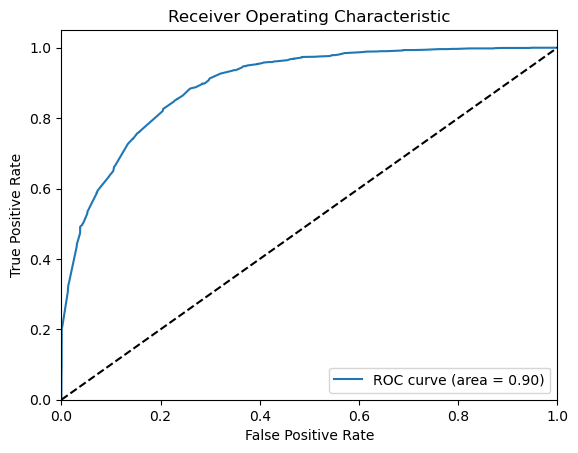

PR AUC: 0.7555701497196122


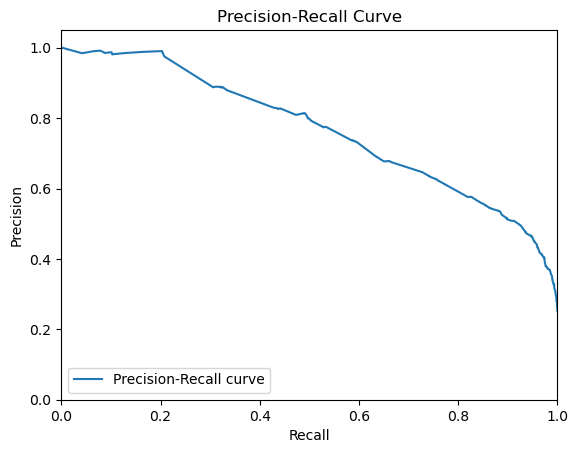

 62%|██████▏   | 8/13 [04:24<01:19, 15.92s/it]


Confusion Matrix:
 [[4247  258]
 [ 611  912]]


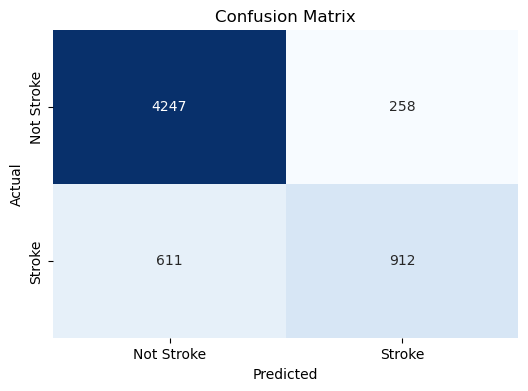


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.94      0.91      4505
      Stroke       0.78      0.60      0.68      1523

    accuracy                           0.86      6028
   macro avg       0.83      0.77      0.79      6028
weighted avg       0.85      0.86      0.85      6028

ROC-AUC: 0.914750517955172


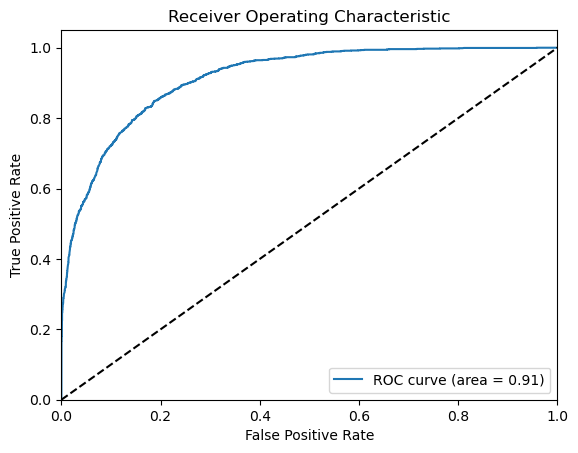

PR AUC: 0.809115417973013


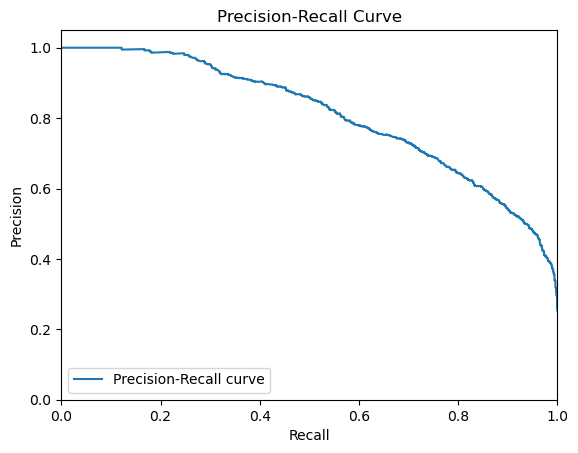

 69%|██████▉   | 9/13 [04:29<00:50, 12.53s/it]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar


Confusion Matrix:
 [[4205  300]
 [ 501 1022]]


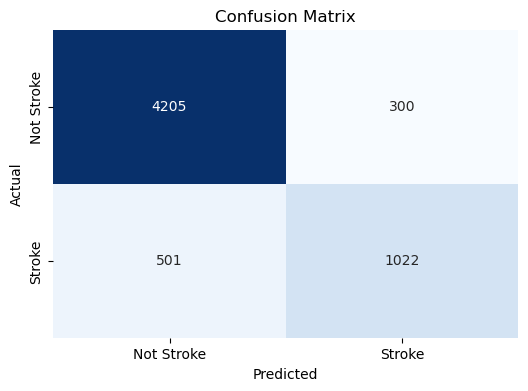


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.93      0.91      4505
      Stroke       0.77      0.67      0.72      1523

    accuracy                           0.87      6028
   macro avg       0.83      0.80      0.82      6028
weighted avg       0.86      0.87      0.86      6028

ROC-AUC: 0.922270869967928


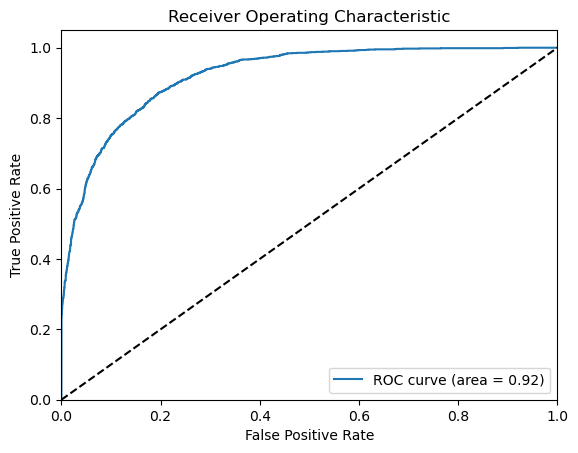

PR AUC: 0.8232540238669355


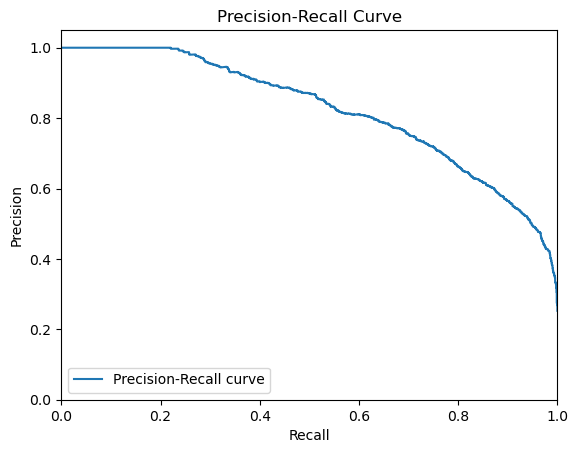

 77%|███████▋  | 10/13 [04:48<00:43, 14.54s/it]e:\anaconda\Lib\site-packages\xgboost\training.py:200: UserWarning: [09:57:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4203  302]
 [ 494 1029]]


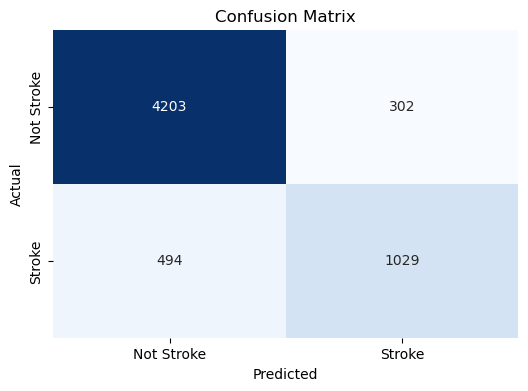


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.93      0.91      4505
      Stroke       0.77      0.68      0.72      1523

    accuracy                           0.87      6028
   macro avg       0.83      0.80      0.82      6028
weighted avg       0.86      0.87      0.86      6028

ROC-AUC: 0.9201276323163217


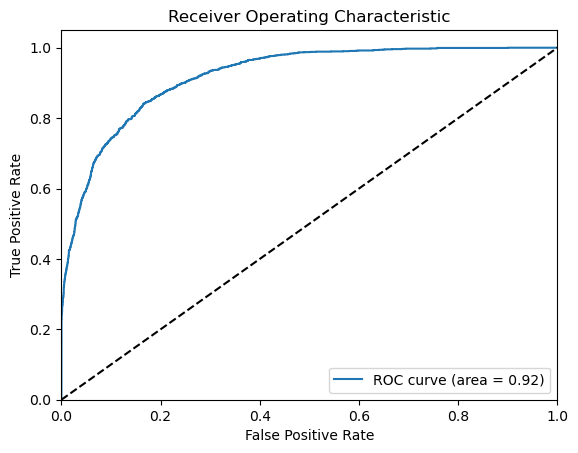

PR AUC: 0.8203677133390683


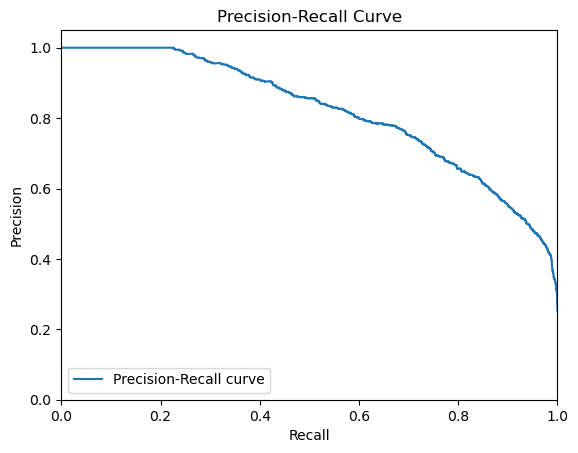

 85%|████████▍ | 11/13 [04:54<00:23, 11.74s/it]


Confusion Matrix:
 [[4213  292]
 [ 510 1013]]


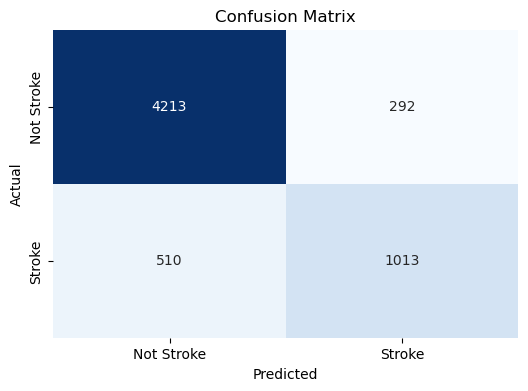


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4505
      Stroke       0.78      0.67      0.72      1523

    accuracy                           0.87      6028
   macro avg       0.83      0.80      0.81      6028
weighted avg       0.86      0.87      0.86      6028

ROC-AUC: 0.9228140761377706


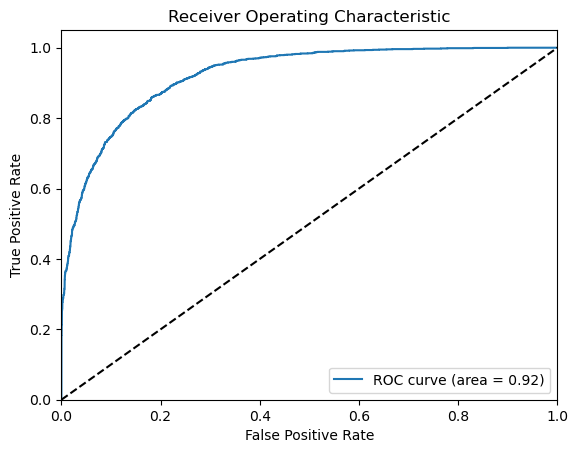

PR AUC: 0.8244999827079604


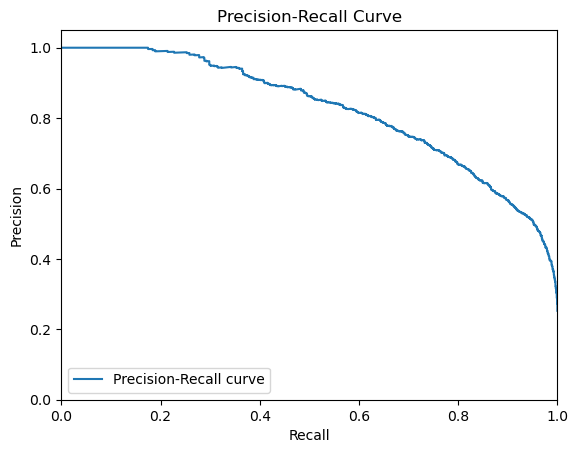

 92%|█████████▏| 12/13 [05:07<00:12, 12.20s/it]

[LightGBM] [Info] Number of positive: 5983, number of negative: 18128
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014196 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 666
[LightGBM] [Info] Number of data points in the train set: 24111, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.248144 -> initscore=-1.108536
[LightGBM] [Info] Start training from score -1.108536

Confusion Matrix:
 [[4220  285]
 [ 519 1004]]


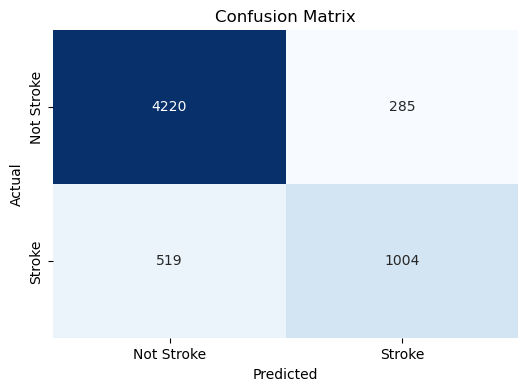


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4505
      Stroke       0.78      0.66      0.71      1523

    accuracy                           0.87      6028
   macro avg       0.83      0.80      0.81      6028
weighted avg       0.86      0.87      0.86      6028

ROC-AUC: 0.9214324493905145


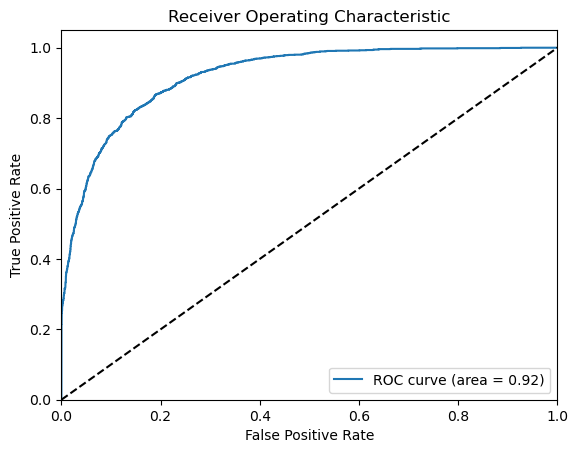

PR AUC: 0.8209471492547357


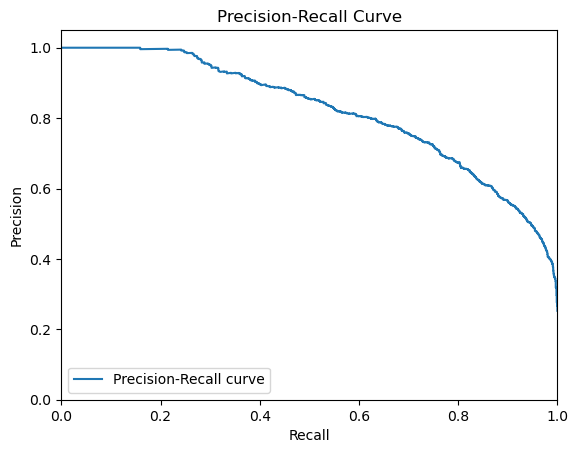

100%|██████████| 13/13 [05:13<00:00, 24.09s/it]


In [42]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

In [43]:
reses = pd.DataFrame(results)

In [49]:
reses

,Logistic Regression,KNN,SVC,Decision Tree,Naive Bayes,Random Forest,Extra Trees,AdaBoost,Gradient Boosting,Hist Gradient Boosting,XGBoost,CatBoost,LightGBM
Train Accuracy,0.821202,0.895566,0.796607,0.999959,0.795488,0.999876,0.999959,0.848617,0.867446,0.887811,0.907636,0.898677,0.888930
Test Accuracy,0.817352,0.847711,0.793132,0.799104,0.790975,0.846715,0.836596,0.842402,0.855839,0.867120,0.867950,0.866954,0.866622
Train Precision,0.719769,0.817599,0.744449,1.000000,0.683020,0.999833,1.000000,0.748456,0.799484,0.816165,0.853406,0.843956,0.822313
Test Precision,0.709325,0.710508,0.748201,0.597867,0.679400,0.731991,0.702560,0.736973,0.779487,0.773071,0.773103,0.776245,0.778898
Train Recall,0.457630,0.745445,0.274611,0.999833,0.328096,0.999666,0.999833,0.587331,0.621762,0.707170,0.757981,0.725890,0.704663
Test Recall,0.469468,0.670387,0.273145,0.625739,0.326986,0.620486,0.612607,0.585030,0.598818,0.671044,0.675640,0.665135,0.659225
Train F1 Score,0.559518,0.779857,0.401221,0.999916,0.443265,0.999749,0.999916,0.658176,0.699511,0.757768,0.802868,0.780483,0.758956
Test F1 Score,0.564994,0.689865,0.400192,0.611485,0.441489,0.671642,0.654507,0.652269,0.677312,0.718453,0.721093,0.716407,0.714083
Train Balanced Accuracy,0.699413,0.845279,0.621750,0.999916,0.638921,0.999805,0.999916,0.761091,0.785147,0.827300,0.857504,0.840797,0.827205
Test Balanced Accuracy,0.702215,0.789023,0.621034,0.741726,0.637411,0.771841,0.762463,0.757221,0.770774,0.802226,0.804302,0.800159,0.797981
